# Breast Cancer Diagnostic Prediction System
### DevSphere AI & Machine Learning Internship — Week 6

**Project Objective**

This project develops a machine learning classification system using the Breast Cancer Wisconsin dataset available through Scikit-learn. It demonstrates data preprocessing, model training, hyperparameter tuning, performance evaluation, visualization, and prediction on user-provided measurements.

**Workflow**
1. Load and explore the dataset.
2. Prepare the features and target labels.
3. Split the data into training and testing sets.
4. Train and compare machine learning models.
5. Tune model hyperparameters.
6. Evaluate performance using classification metrics and visualizations.
7. Generate predictions using the trained model.

**Tools and Libraries:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Joblib.

**Important Note:** This project is for educational purposes only. It is not a clinically validated diagnostic tool and must not be used to make medical decisions.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Pandas version: 3.0.5
NumPy version: 2.5.2


In [2]:
# Load the Breast Cancer Wisconsin dataset
dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset loaded successfully.")
print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", list(dataset.target_names))

Dataset loaded successfully.
Number of records: 569
Number of features: 30
Target classes: [np.str_('malignant'), np.str_('benign')]


In [3]:
# Display the first five records
display(X.head())

print("Dataset dimensions:", X.shape)

print("\nFeature information:")
X.info()

print("\nStatistical summary:")
display(X.describe().T)

print("\nTarget class distribution:")
print(y.map(dict(enumerate(dataset.target_names))).value_counts())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset dimensions: (569, 30)

Feature information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null  

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Target class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


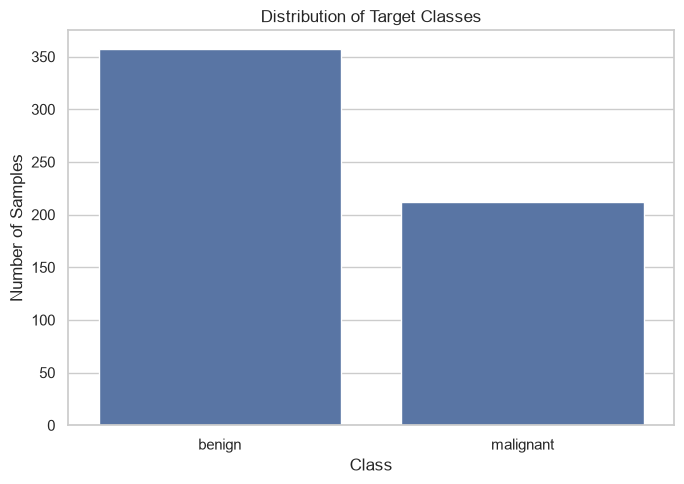

In [4]:
class_counts = y.map(dict(enumerate(dataset.target_names))).value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Distribution of Target Classes")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [5]:
# Check for missing values and duplicate records
print("Missing values before preprocessing:", int(X.isnull().sum().sum()))
print("Duplicate records:", int(X.duplicated().sum()))

# Replace infinite values, if any, with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values using each feature's median
X = X.fillna(X.median())

print("\nMissing values after preprocessing:", int(X.isnull().sum().sum()))
print("Final feature matrix shape:", X.shape)

# Split the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Preprocessing completed successfully.")

Missing values before preprocessing: 0
Duplicate records: 0

Missing values after preprocessing: 0
Final feature matrix shape: (569, 30)

Training samples: 455
Testing samples: 114
Preprocessing completed successfully.


In [6]:
# Build a preprocessing and classification pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression trained successfully.")
print("Test accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))

Logistic Regression trained successfully.
Test accuracy: 0.9825


In [7]:
# Build and train the Random Forest classifier
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest trained successfully.")
print("Test accuracy:", round(
    accuracy_score(y_test, random_forest_predictions), 4
))

Random Forest trained successfully.
Test accuracy: 0.9474


In [8]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }


comparison_results = pd.DataFrame([
    evaluate_model("Logistic Regression", logistic_model, X_test, y_test),
    evaluate_model("Random Forest", random_forest_model, X_test, y_test)
])

display(comparison_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Random Forest,0.9474,0.9714,0.9444,0.9577,0.9944


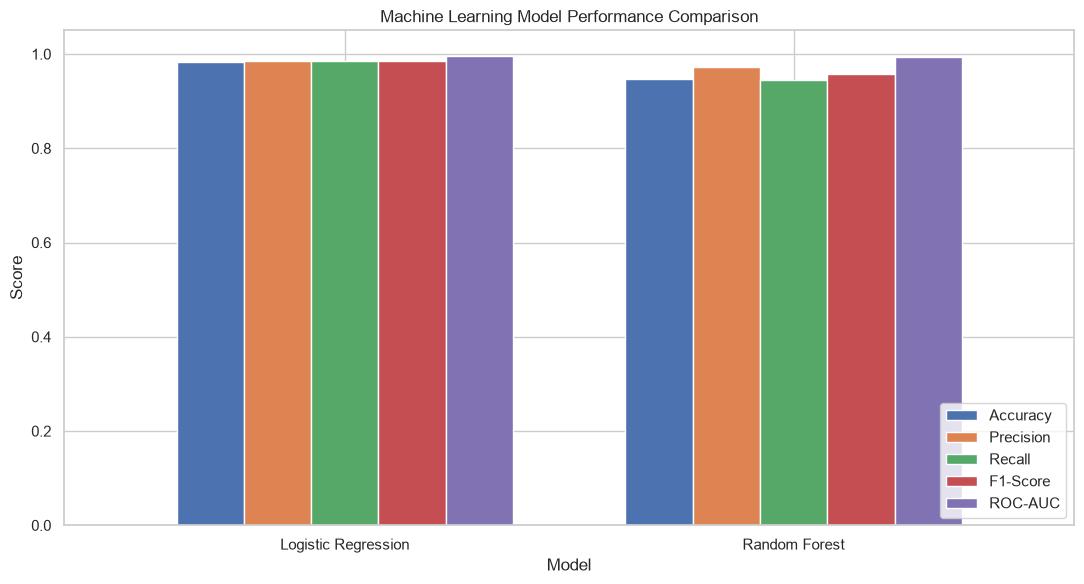

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

comparison_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    width=0.75
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
# Tune Logistic Regression using 5-fold cross-validation
parameter_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=parameter_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Hyperparameter tuning completed.")
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", round(grid_search.best_score_, 4))

Hyperparameter tuning completed.
Best parameters: {'classifier__C': 0.1, 'classifier__solver': 'liblinear'}
Best cross-validation accuracy: 0.9802


In [11]:
final_predictions = best_model.predict(X_test)
final_probabilities = best_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(y_test, final_predictions, zero_division=0),
    "Recall": recall_score(y_test, final_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, final_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, final_probabilities)
}

print("FINAL MODEL EVALUATION")
print("-" * 35)

for metric, score in final_metrics.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=dataset.target_names,
        zero_division=0
    )
)

FINAL MODEL EVALUATION
-----------------------------------
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-Score: 0.9861
ROC-AUC: 0.9960

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



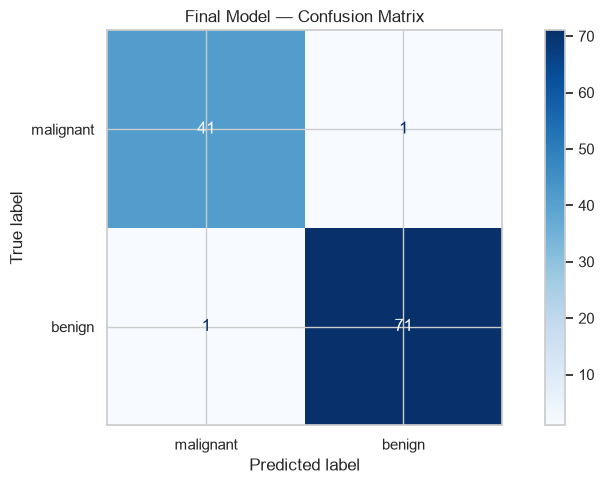

In [12]:
conf_matrix = confusion_matrix(y_test, final_predictions)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix,
    display_labels=dataset.target_names
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Final Model — Confusion Matrix")
plt.tight_layout()
plt.show()

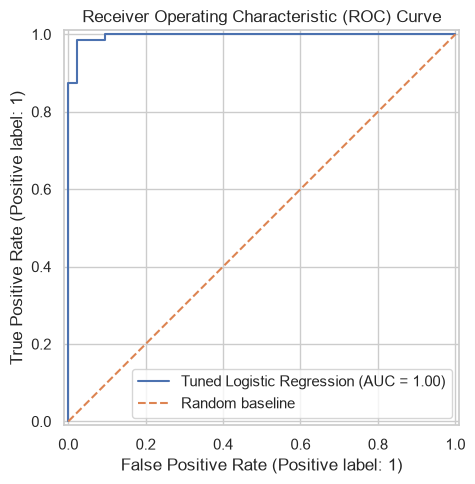

In [13]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    name="Tuned Logistic Regression"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
BASE_DIR = Path.cwd()

# Handle execution from either the project root or notebook folder
if BASE_DIR.name == "notebook":
    BASE_DIR = BASE_DIR.parent

MODEL_DIR = BASE_DIR / "model"
REPORT_DIR = BASE_DIR / "report"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "model": best_model,
    "feature_names": list(dataset.feature_names),
    "target_names": list(dataset.target_names)
}

joblib.dump(model_bundle, MODEL_DIR / "prediction_model.joblib")

comparison_results.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

pd.DataFrame(
    [final_metrics]
).to_csv(
    REPORT_DIR / "final_evaluation_metrics.csv",
    index=False
)

with open(REPORT_DIR / "evaluation_report.txt", "w", encoding="utf-8") as file:
    file.write("BREAST CANCER PREDICTION SYSTEM — EVALUATION REPORT\n")
    file.write("=" * 55 + "\n\n")
    file.write(f"Training samples: {len(X_train)}\n")
    file.write(f"Testing samples: {len(X_test)}\n")
    file.write(f"Best parameters: {grid_search.best_params_}\n\n")

    for metric, score in final_metrics.items():
        file.write(f"{metric}: {score:.4f}\n")

print("Final model and evaluation reports saved successfully.")
print("Model:", MODEL_DIR / "prediction_model.joblib")
print("Reports:", REPORT_DIR)

Final model and evaluation reports saved successfully.
Model: C:\Users\Ammar Akram\OneDrive\Desktop\DevSphere_Internship\DevSphere_ML_Week6\model\prediction_model.joblib
Reports: C:\Users\Ammar Akram\OneDrive\Desktop\DevSphere_Internship\DevSphere_ML_Week6\report


In [15]:
# Demonstrate prediction using one test sample
sample_index = 0

sample_input = X_test.iloc[[sample_index]]
actual_class = int(y_test.iloc[sample_index])

predicted_class = int(best_model.predict(sample_input)[0])
class_probabilities = best_model.predict_proba(sample_input)[0]

print("USER-INPUT PREDICTION DEMONSTRATION")
print("=" * 40)
print("Actual class:", dataset.target_names[actual_class])
print("Predicted class:", dataset.target_names[predicted_class])

print("\nEstimated class probabilities:")
for class_index, class_name in enumerate(dataset.target_names):
    print(f"{class_name.title()}: {class_probabilities[class_index]:.2%}")

print("\nSample feature measurements:")
display(sample_input.T.rename(columns={sample_input.index[0]: "Value"}))

USER-INPUT PREDICTION DEMONSTRATION
Actual class: malignant
Predicted class: malignant

Estimated class probabilities:
Malignant: 100.00%
Benign: 0.00%

Sample feature measurements:


,Value
mean radius,19.550000
mean texture,28.770000
mean perimeter,133.600000
mean area,1207.000000
mean smoothness,0.092600
mean compactness,0.206300
mean concavity,0.178400
mean concave points,0.114400
mean symmetry,0.189300
mean fractal dimension,0.062320
